# Audio — Pengenalan Emosi dari Suara (Speech Emotion Recognition)
**Kapan dipakai:** menebak emosi dari rekaman suara (penelepon call center, stres/depresi,
kepuasan pelanggan).

**Penting:** split harus **per pembicara**. Kalau aktor yang sama ada di train dan validasi,
model menghafal suara orangnya dan skor validasi terlalu tinggi (dibuktikan di sel Evaluasi).

**Langkah:**
1. Ubah tiap rekaman menjadi feature: embedding wav2vec2 satu lapisan (`LAYER`), atau MFCC.
2. Split per pembicara, latih model, evaluasi.
3. Latih ulang di semua data train, simpan submission.

**Data demo:** RAVDESS (12 aktor), 8 emosi, kalimat yang diucapkan sama semua.

In [1]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from transformers import AutoFeatureExtractor, Wav2Vec2Model

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/audio/emosi"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/ravdess.csv"
PRETRAINED_FOLDER = "../../../pretrained/wav2vec2_base"

ID_COL = "id"
PATH_COL = "path"           # kolom berisi nama file audio, relatif terhadap DATA_FOLDER
LABEL_COL = "emosi"
GROUP_COL = "speaker"       # validasi dipisah per kolom ini
TEST_SPEAKERS = ["aktor10", "aktor11", "aktor12"]   # data demo: aktor ini dijadikan test
SAMPLE_RATE = 16000
CLIP_LENGTH = 3 * SAMPLE_RATE   # 3 detik, setelah hening di awal dan akhir dibuang
LAYER = 8                   # lapisan wav2vec2 (0 = paling awal, 12 = terakhir), coba juga 4 atau 12
N_MFCC = 20
BATCH_SIZE = 16             # kecilkan bila memori GPU penuh
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data
Data demo hanya satu file, jadi 3 aktor dipisah sebagai test.
Saat lomba: ganti sel ini dengan `train = pd.read_csv(...)` dan `test = pd.read_csv(...)`.

In [3]:
data = pd.read_csv(DATA_CSV)
is_test = data[GROUP_COL].isin(TEST_SPEAKERS)
train = data[~is_test].reset_index(drop=True)
test = data[is_test].reset_index(drop=True)
test = test.drop(columns=LABEL_COL)
print(train.shape, test.shape)
print(train.isna().sum())
train.head()

(540, 5) (180, 4)
id            0
path          0
emosi         0
intensitas    0
speaker       0
dtype: int64


,id,path,emosi,intensitas,speaker
0,0,ravdess/03-01-01-01-01-01-01.wav,netral,1,aktor01
1,1,ravdess/03-01-01-01-01-02-01.wav,netral,1,aktor01
2,2,ravdess/03-01-01-01-02-01-01.wav,netral,1,aktor01
3,3,ravdess/03-01-01-01-02-02-01.wav,netral,1,aktor01
4,4,ravdess/03-01-02-01-01-01-01.wav,tenang,1,aktor01


## EDA: jumlah per emosi dan contoh gelombang suara

emosi
tenang      72
senang      72
sedih       72
marah       72
jijik       72
takut       72
terkejut    72
netral      36
Name: count, dtype: int64
intensitas   1   2
emosi             
jijik       36  36
marah       36  36
netral      36   0
sedih       36  36
senang      36  36
takut       36  36
tenang      36  36
terkejut    36  36


durasi contoh (detik): 3.3033125


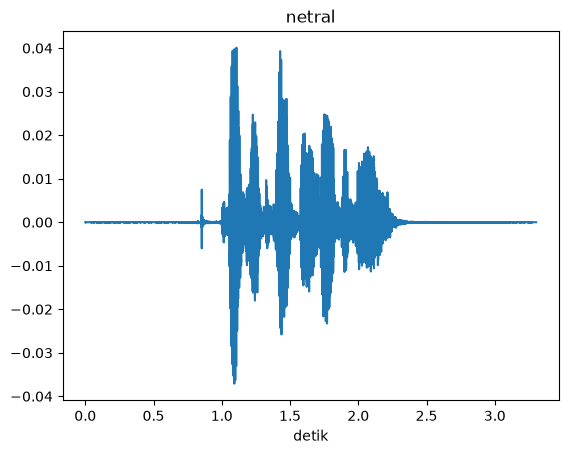

In [4]:
print(train[LABEL_COL].value_counts())
print(pd.crosstab(train[LABEL_COL], train["intensitas"]))
example_audio, _ = librosa.load(f"{DATA_FOLDER}/{train[PATH_COL][0]}", sr=SAMPLE_RATE)
print("durasi contoh (detik):", len(example_audio) / SAMPLE_RATE)
seconds = np.arange(len(example_audio)) / SAMPLE_RATE
plt.plot(seconds, example_audio)
plt.title(train[LABEL_COL][0])
plt.xlabel("detik")
plt.show()

## Langkah 1a — feature embedding wav2vec2 (satu lapisan)
`output_hidden_states=True` membuat wav2vec2 mengembalikan semua lapisan; kita ambil lapisan
`LAYER` lalu rata-rata di sumbu waktu.

In [5]:
feature_extractor = AutoFeatureExtractor.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder = Wav2Vec2Model.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder.eval()
encoder = encoder.to(DEVICE)


def load_clip(path):
    audio, _ = librosa.load(f"{DATA_FOLDER}/{path}", sr=SAMPLE_RATE)
    audio, _ = librosa.effects.trim(audio, top_db=30)   # buang hening di awal dan akhir
    audio = np.pad(audio, (0, CLIP_LENGTH))
    return audio[:CLIP_LENGTH]


def extract_embeddings(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        clips = []
        for path in paths[start:start + BATCH_SIZE]:
            clips.append(load_clip(path))
        inputs = feature_extractor(clips, sampling_rate=SAMPLE_RATE, return_tensors="pt")
        with torch.no_grad():
            output = encoder(inputs.input_values.to(DEVICE), output_hidden_states=True)
        mean_over_time = output.hidden_states[LAYER].mean(dim=1)
        batches.append(mean_over_time.cpu().numpy())
    return np.concatenate(batches)


# coba pada 2 rekaman
example = extract_embeddings(list(train[PATH_COL][:2]))
print("ukuran embedding 2 rekaman:", example.shape)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: ../../../pretrained/wav2vec2_base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ukuran embedding 2 rekaman: (2, 768)


## Langkah 1b — feature MFCC + energi + nada (alternatif tanpa GPU)
Nada (pitch) dan energi (RMS) penting untuk emosi: marah = keras dan tinggi, sedih = pelan.

In [6]:
def extract_mfcc(paths):
    rows = []
    for path in paths:
        audio = load_clip(path)
        mfcc = librosa.feature.mfcc(y=audio, sr=SAMPLE_RATE, n_mfcc=N_MFCC)
        rms = librosa.feature.rms(y=audio)
        pitch = librosa.yin(audio, fmin=60, fmax=400, sr=SAMPLE_RATE)
        extra = [rms.mean(), rms.std(), np.median(pitch), pitch.std()]
        rows.append(np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1), extra]))
    return np.stack(rows)


# coba pada 2 rekaman
example = extract_mfcc(list(train[PATH_COL][:2]))
print("ukuran feature MFCC 2 rekaman:", example.shape)

ukuran feature MFCC 2 rekaman: (2, 44)


## Hitung feature semua rekaman (pilih satu pasang baris)

In [7]:
X = extract_embeddings(list(train[PATH_COL]))
X_test = extract_embeddings(list(test[PATH_COL]))
# X = extract_mfcc(list(train[PATH_COL]))          # tanpa GPU, lebih cepat, biasanya lebih lemah
# X_test = extract_mfcc(list(test[PATH_COL]))
y = train[LABEL_COL]
print(X.shape, X_test.shape)

(540, 768) (180, 768)


## Split per pembicara (aktor validasi tidak pernah dilihat saat train)

In [8]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
splits = splitter.split(X, y, groups=train[GROUP_COL])
train_rows, val_rows = next(splits)
print("aktor validasi:", sorted(train[GROUP_COL][val_rows].unique()))

aktor validasi: ['aktor02', 'aktor06', 'aktor08']


## Langkah 2 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [9]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
# model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
# model = make_pipeline(StandardScaler(), SVC(C=10, random_state=SEED))
# model = make_pipeline(StandardScaler(), LGBMClassifier(verbose=-1, random_state=SEED))

model.fit(X[train_rows], y[train_rows])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](8,)","['jijik','marah','netral',...,'takut','tenang','terkejut']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Evaluasi: split per aktor (jujur) vs split acak (bocor suara aktor)

F1 macro split per aktor: 0.6847144609513425


              precision    recall  f1-score   support

       jijik       0.91      0.83      0.87        24
       marah       1.00      0.67      0.80        24
      netral       0.52      0.92      0.67        12
       sedih       0.44      0.62      0.52        24
      senang       0.67      0.58      0.62        24
       takut       0.78      0.29      0.42        24
      tenang       0.61      0.92      0.73        24
    terkejut       0.90      0.79      0.84        24

    accuracy                           0.69       180
   macro avg       0.73      0.70      0.68       180
weighted avg       0.74      0.69      0.69       180



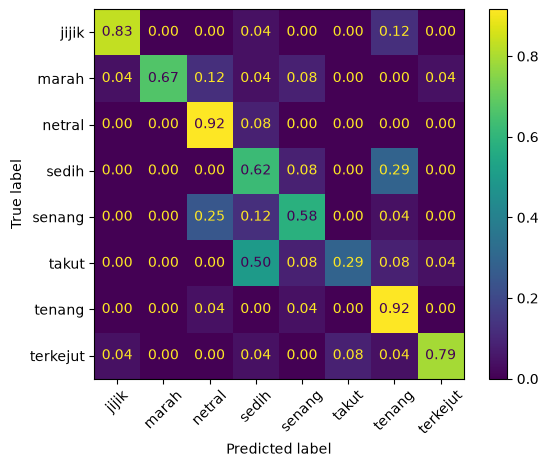

F1 macro split acak (terlalu optimis): 0.8033691636900944


In [10]:
pred_val = model.predict(X[val_rows])
print("F1 macro split per aktor:", f1_score(y[val_rows], pred_val, average="macro"))
print(classification_report(y[val_rows], pred_val))
ConfusionMatrixDisplay.from_predictions(y[val_rows], pred_val, normalize="true",
                                        values_format=".2f", xticks_rotation=45)
plt.show()

# pembanding: split acak, aktor yang sama bisa ada di train dan validasi
random_train, random_val = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y,
                                            random_state=SEED)
random_model = clone(model)
random_model.fit(X[random_train], y[random_train])
pred_random = random_model.predict(X[random_val])
print("F1 macro split acak (terlalu optimis):",
      f1_score(y[random_val], pred_random, average="macro"))

## Langkah 3 — latih ulang di semua data + submission

In [11]:
model.fit(X, y)
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test[ID_COL]
submission["emosi"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,emosi
0,540,tenang
1,541,sedih
2,542,sedih
3,543,tenang
4,544,sedih


## Cek dengan kunci jawaban (HAPUS saat lomba)
Label aktor test hanya ada di data demo.

In [12]:
test_key = data[is_test][LABEL_COL]
print("F1 macro test (kunci demo):", f1_score(test_key, predictions, average="macro"))

F1 macro test (kunci demo): 0.5860485144877987
